# Drone Weight — Constrained Optimization

## Formulation

$$
\min_{i,j,n}\; W_{\text{total}}
= W_{\text{airframe}} + 4(m_{\text{motor},i}+m_{\text{prop},i})
+ n\,m_{\text{batt},j} + m_{\text{payload}}
$$

subject to

$$
\begin{aligned}
&\text{(C1)}\quad 4T_{\max,i}/W_{\text{total}} \ge 2.0 && \text{static thrust}\\
&\text{(C2)}\quad 60\,nE_j\eta / P_h \ge t_{\text{req}},\; P_h=4V_iI_i(W/4) && \text{endurance}\\
&\text{(C3)}\quad D_{\min}\le D_i\le D_{\max} && \text{prop/frame}\\
&\text{(C4)}\quad S_i\le S_{\max,i} && \text{voltage}\\
&\text{(C5)}\quad I_h \le nC_{\text{rate},j}C_j/1000 && \text{discharge}\\
&\text{(C6)}\quad W_{\text{total}}\le 2500\ \text{g} && \text{extrapolation cap}
\end{aligned}
$$

Every mass, thrust and current value is measured/catalogued. `W_airframe` and the payload
are explicit design inputs; the frame mass is **not** present in the dataset and is varied
by ±30 % in the sensitivity study.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd, numpy as np
pd.set_option("display.width", 240)
from src.config import SCENARIOS
from src.optimization import Catalogue, DesignProblem, component_table, sensitivity

cat = Catalogue.load()
print("propulsion groups:", len(cat.groups), "| batteries:", len(cat.batteries))
pd.DataFrame(SCENARIOS).T

propulsion groups: 392 | batteries: 326


,label,min_prop_in,max_prop_in,payload_kg,airframe_g,endurance_min
3inch,3-inch micro class,2.5,3.5,0.2,95.0,8.0
5inch,5-inch freestyle / cinematic class,4.5,5.5,0.5,245.0,10.0
7inch,7-inch long-range / heavy-lift class,6.5,7.5,0.75,450.0,12.0


## Exact solution (global optimum by enumeration)

In [2]:
results = {}
for name in SCENARIOS:
    p = DesignProblem(cat, SCENARIOS[name])
    best, designs = p.exhaustive()
    results[name] = (p, best, designs)
    print(f"{name:6s} candidates={len(designs):6d} feasible={designs.feasible.sum():6d} "
          f"optimum={best['w_total_g']:.1f} g  TWR={best['twr']:.2f}  "
          f"endurance={best['endurance_min']:.1f} min")

3inch  candidates= 12600 feasible=  2889 optimum=460.1 g  TWR=3.04  endurance=8.6 min


5inch  candidates= 46956 feasible=  7218 optimum=1138.5 g  TWR=3.34  endurance=11.3 min


7inch  candidates=  8229 feasible=   285 optimum=1715.7 g  TWR=4.93  endurance=12.4 min


In [3]:
for name,(p,best,designs) in results.items():
    print("="*70)
    print(name, "->", round(best["w_total_g"],1), "g")
    for k in ["motor_model","motor_mass_g","prop_key","prop_diameter_in","prop_mass_g",
              "cells","battery_model","battery_mass_g","n_packs","twr","endurance_min"]:
        print(f"  {k:22s} {best[k]}")

3inch -> 460.1 g
  motor_model            F1404
  motor_mass_g           9.3
  prop_key               HQProp 3520
  prop_diameter_in       3.5
  prop_mass_g            1.6713358772825133
  cells                  4
  battery_model          RDQ Series 650mAh 4S
  battery_mass_g         60.6
  n_packs                2
  twr                    3.0448263996312255
  endurance_min          8.62249609703827
5inch -> 1138.5 g
  motor_model            2203.5
  motor_mass_g           19.7
  prop_key               Gemfan 5125
  prop_diameter_in       5.1
  prop_mass_g            4.427819304839669
  cells                  6
  battery_model          3000mAh 6S
  battery_mass_g         297.0
  n_packs                1
  twr                    3.3373758135097655
  endurance_min          11.259930368497201
7inch -> 1715.7 g
  motor_model            F90 2806.5
  motor_mass_g           46.6
  prop_key               Gemfan 7042
  prop_diameter_in       7.0
  prop_mass_g            8.08497414735224
  cells

## Component-wise result

In [4]:
comp = pd.concat([component_table({"exact":{"scenario":n,"global_optimum":b}})
                  for n,(p,b,d) in results.items()], ignore_index=True)
comp.round(1)

,component,mass_g,detail,scenario,total_g,share_pct
0,Frame (residual allocation),66.0,airframe input minus avionics,3inch,460.1,14.3
1,Avionics (FC/ESC + camera + VTX),29.0,catalogue median allocation,3inch,460.1,6.3
2,Motors,37.2,4 x F1404,3inch,460.1,8.1
3,Propellers,6.7,4 x HQProp 3520,3inch,460.1,1.5
4,Battery,121.2,2 x RDQ Series 650mAh 4S,3inch,460.1,26.3
5,Payload,200.0,requirement,3inch,460.1,43.5
6,Frame (residual allocation),216.0,airframe input minus avionics,5inch,1138.5,19.0
7,Avionics (FC/ESC + camera + VTX),29.0,catalogue median allocation,5inch,1138.5,2.5
8,Motors,78.8,4 x 2203.5,5inch,1138.5,6.9
9,Propellers,17.7,4 x Gemfan 5125,5inch,1138.5,1.6


## Baseline comparison

In [5]:
import json
res = json.load(open("../outputs/drone_weight/optimization_results.json"))
rows=[]
for k,v in res["scenarios"].items():
    o=v["global_optimum"]; b=v["baseline_median_feasible"]; t=v["baseline_typical_components"]
    rows.append({"scenario":k,"optimized_g":o["w_total_g"],
                 "median_feasible_g":b["w_total_g"],
                 "reduction_vs_median_feasible_pct":v["reduction_vs_median_feasible_pct"],
                 "real_class_plus_payload_g":t["real_class_auw_plus_payload_g"],
                 "real_class_n":t["real_class_n"]})
pd.DataFrame(rows).round(1)

,scenario,optimized_g,median_feasible_g,reduction_vs_median_feasible_pct,real_class_plus_payload_g,real_class_n
0,3inch,460.1,812.9,43.4,453.8,35
1,5inch,1138.5,1668.6,31.8,1154.0,17
2,7inch,1715.7,2198.7,22.0,2647.5,2


The reduction against the **median feasible catalogue build** is 22–43 %. That baseline is
a valid but heavily over-provisioned combination. Against a **real aircraft of the same prop
class plus the same payload**, the optimized 5-inch design is only 1.3 % lighter — a much more
credible statement. Both numbers are reported; neither is hidden.

## Algorithm comparison (pre-computed, 8 seeds × 1,200 evaluations)

In [6]:
comp = pd.read_csv("../outputs/drone_weight/algorithm_comparison.csv")
comp.groupby("algorithm")[["best_feasible_g","mean_feasible_g","sd_feasible_g",
                           "success_rate","gap_to_optimum_pct","mean_time_s"]].mean().round(3)

,best_feasible_g,mean_feasible_g,sd_feasible_g,success_rate,gap_to_optimum_pct,mean_time_s
algorithm,,,,,,
Bayesian (TPE),1106.379,1189.128,49.052,0.208,0.348,2.899
Differential Evolution,1149.009,1208.416,36.128,0.083,4.087,0.089
Genetic Algorithm,1106.379,1197.510,66.213,0.167,0.348,0.063
Grid Search,1243.188,1243.188,0.000,0.000,15.602,0.005
Particle Swarm,1125.026,1204.808,50.717,0.083,1.981,0.052
Random Search,1121.546,1180.373,44.308,0.083,1.809,0.053


In [7]:
comp.groupby(["scenario","algorithm"])["success_rate"].mean().unstack().round(2)

algorithm,Bayesian (TPE),Differential Evolution,Genetic Algorithm,Grid Search,Particle Swarm,Random Search
scenario,,,,,,
3inch,0.00,0.00,0.00,0.0,0.00,0.00
5inch,0.50,0.00,0.12,0.0,0.00,0.00
7inch,0.12,0.25,0.38,0.0,0.25,0.25


**Conclusion.** Exhaustive enumeration is the appropriate method: 8k–47k candidates are
evaluated in under a second and give the certified global optimum with zero variance.
Among heuristics, GA and TPE reach the optimum most often; DE is the most consistent but
converges to slightly worse points; grid search is dominated. No heuristic beats exact
enumeration on any criterion.

## Sensitivity (5-inch)

In [8]:
sens = pd.read_csv("../outputs/drone_weight/sensitivity_analysis.csv")
piv = sens[sens.parameter!="baseline"].pivot_table(index="value", columns="parameter",
                                                   values="optimum_g")
piv.round(1)

parameter,airframe_scale,endurance_min,min_twr,payload_kg
value,,,,
0.00,NaN,NaN,NaN,473.7
0.25,NaN,NaN,NaN,741.5
0.50,NaN,NaN,NaN,1138.5
0.70,1017.0,NaN,NaN,NaN
0.75,NaN,NaN,NaN,1449.2
0.85,1053.8,NaN,NaN,NaN
1.00,1138.5,NaN,NaN,1791.5
1.15,1175.3,NaN,NaN,NaN
1.30,1212.0,NaN,NaN,NaN


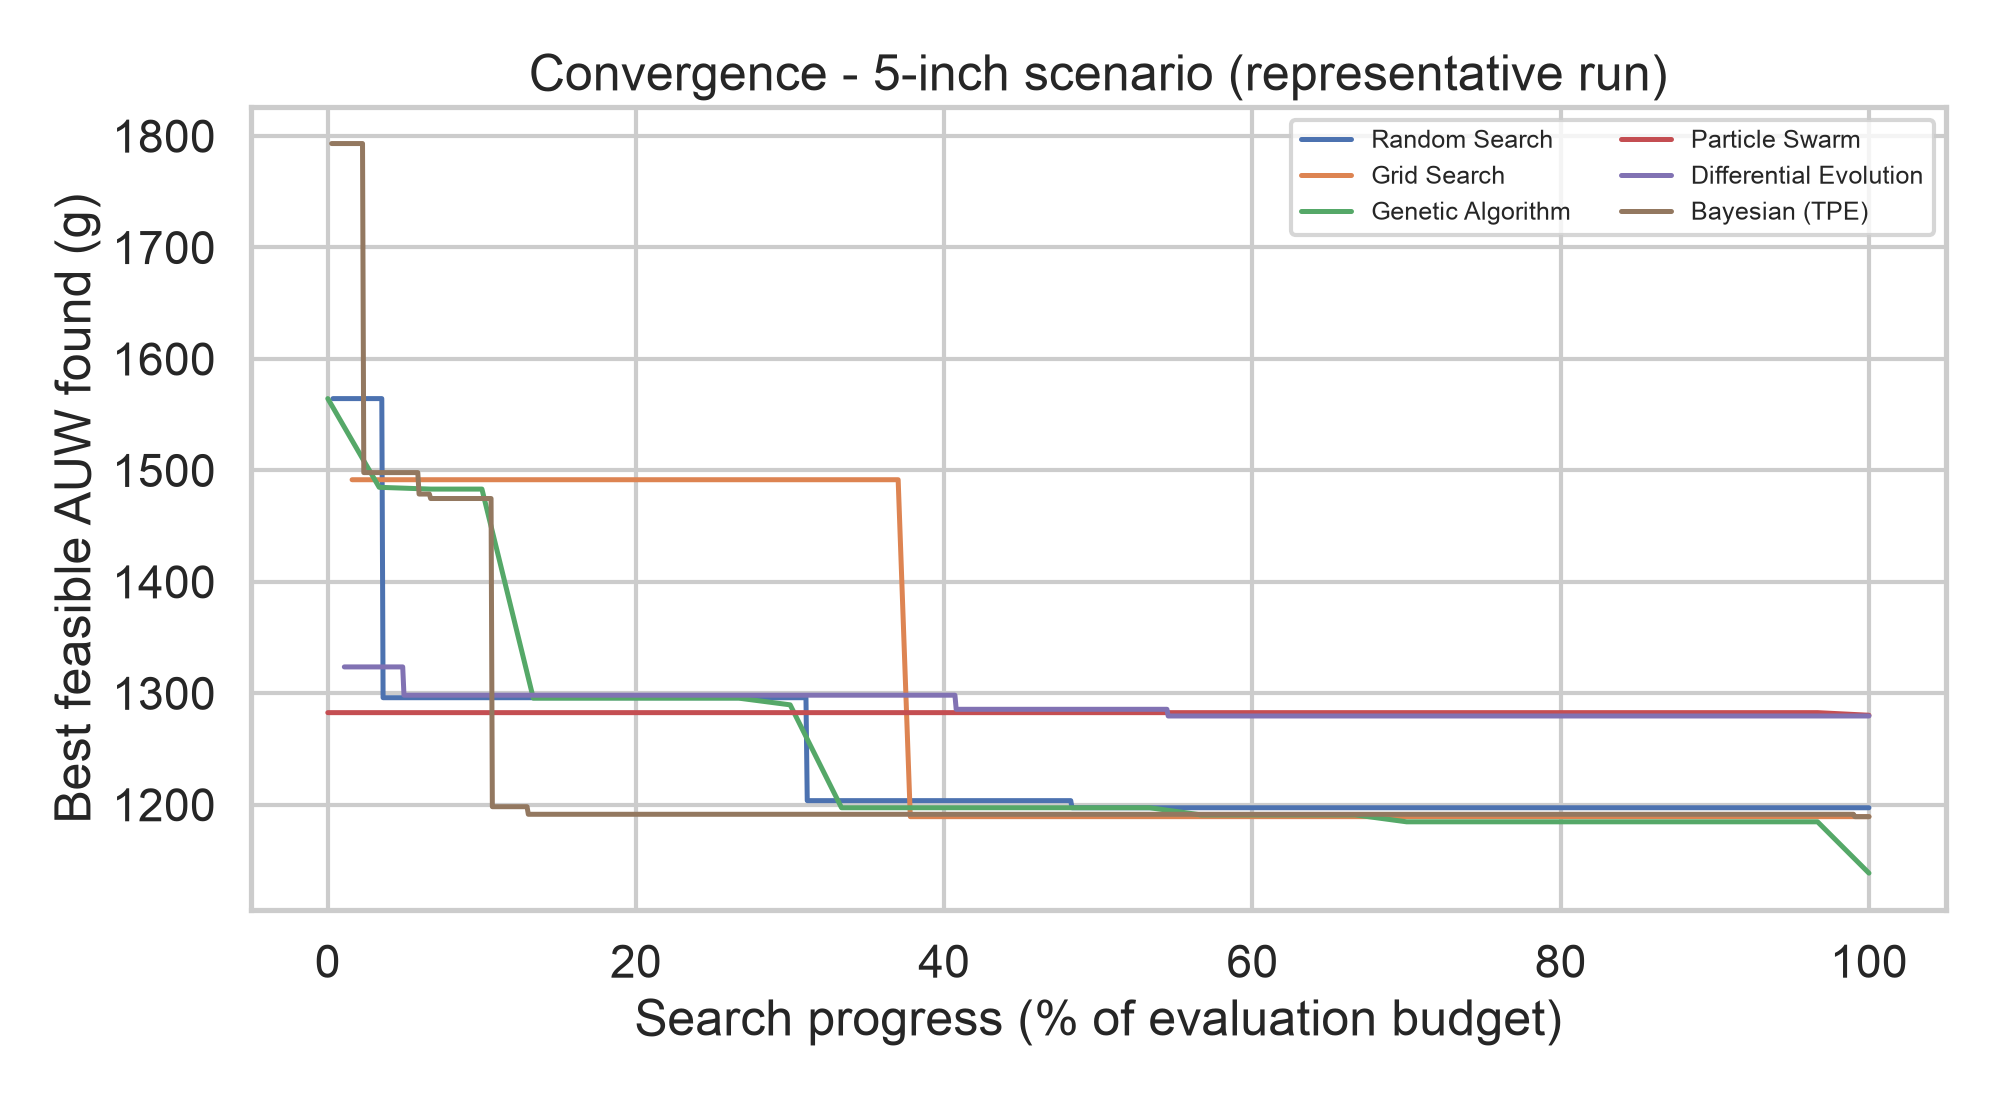

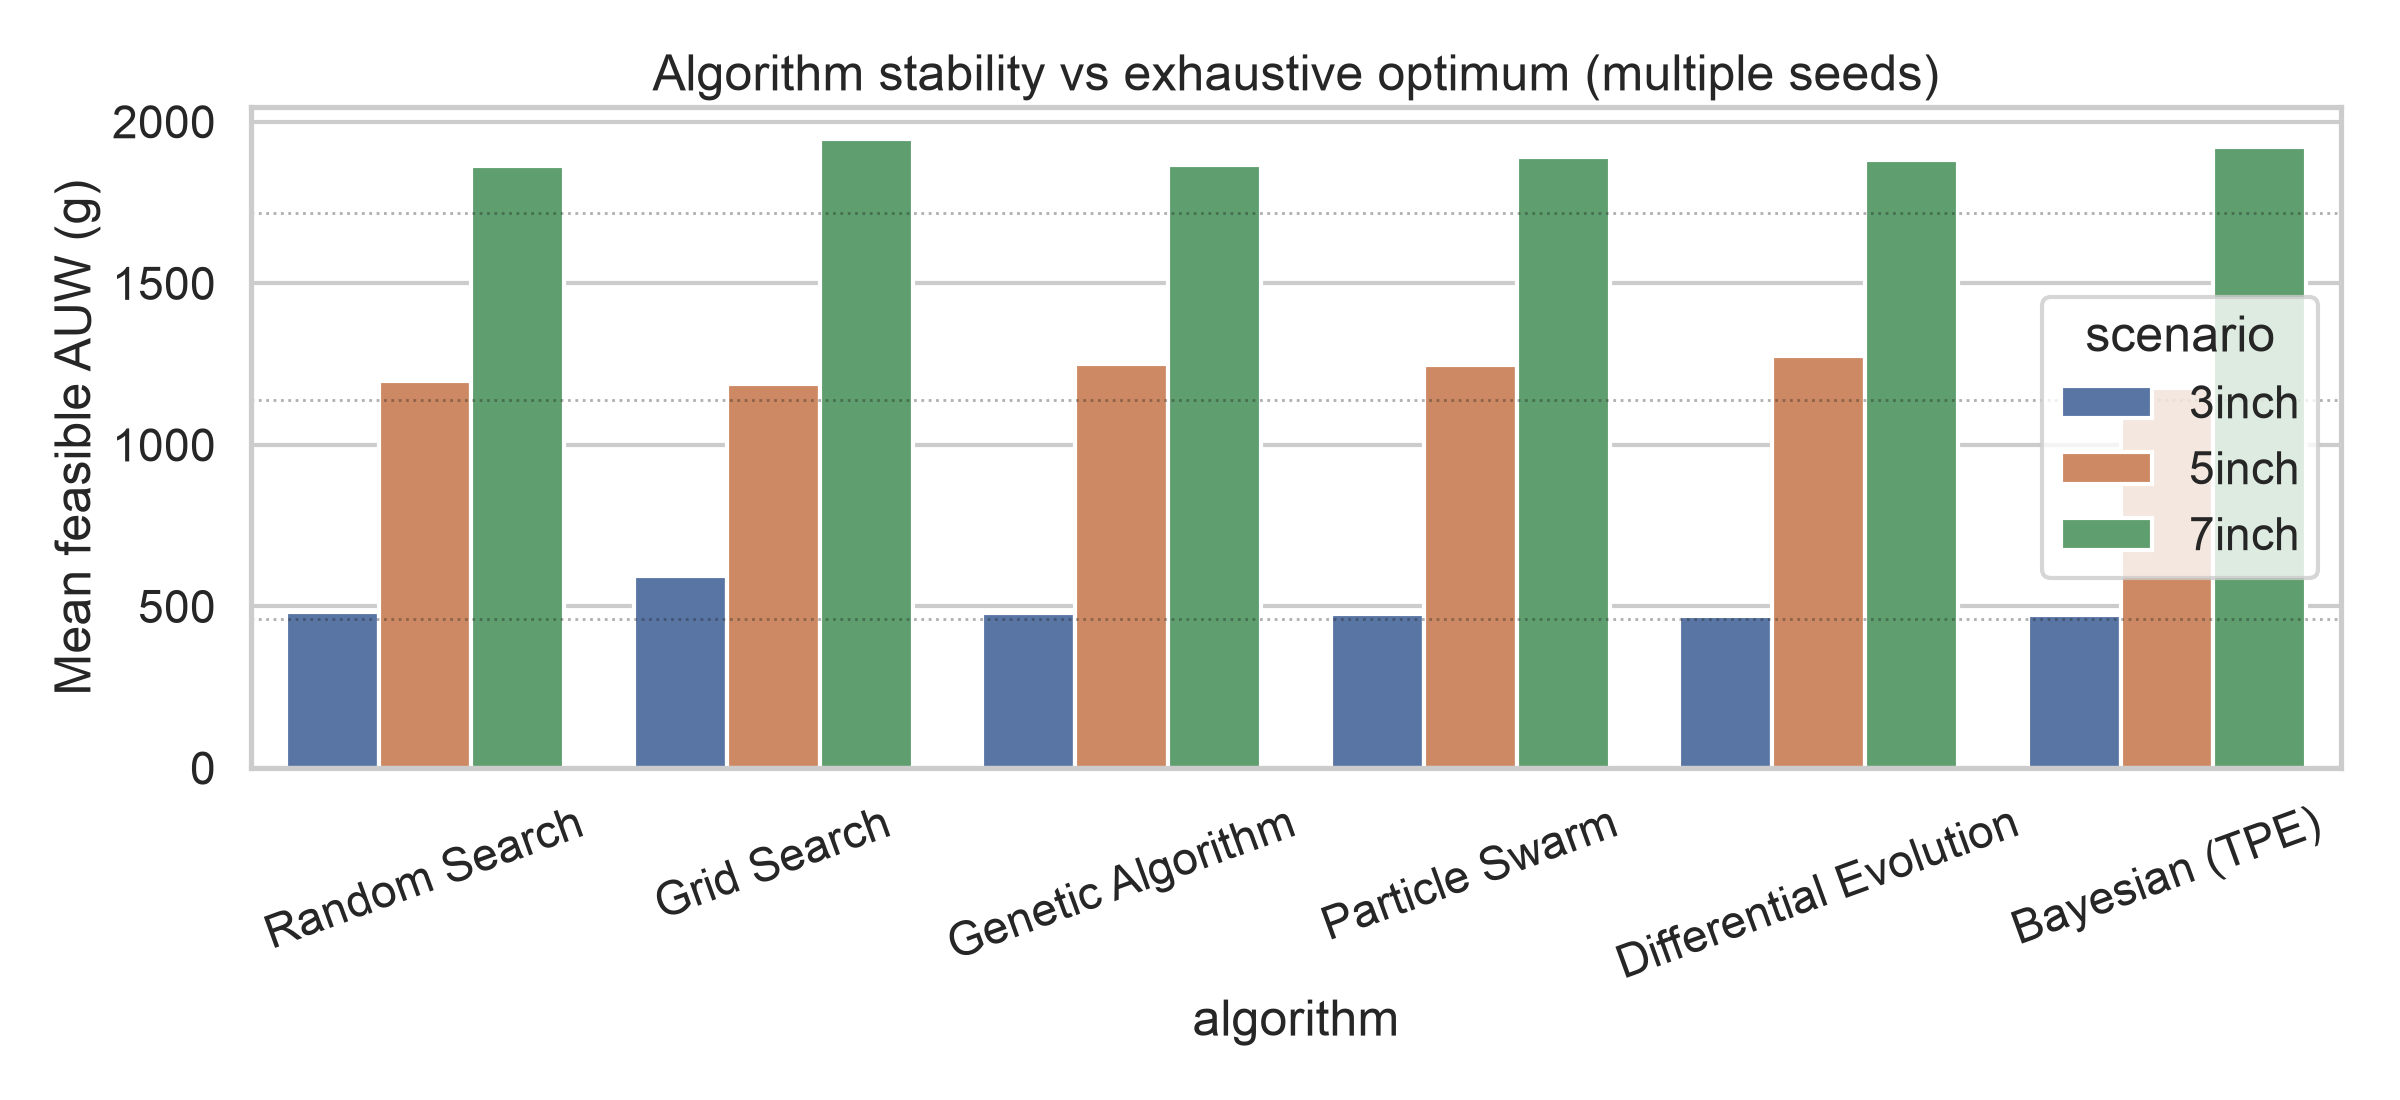

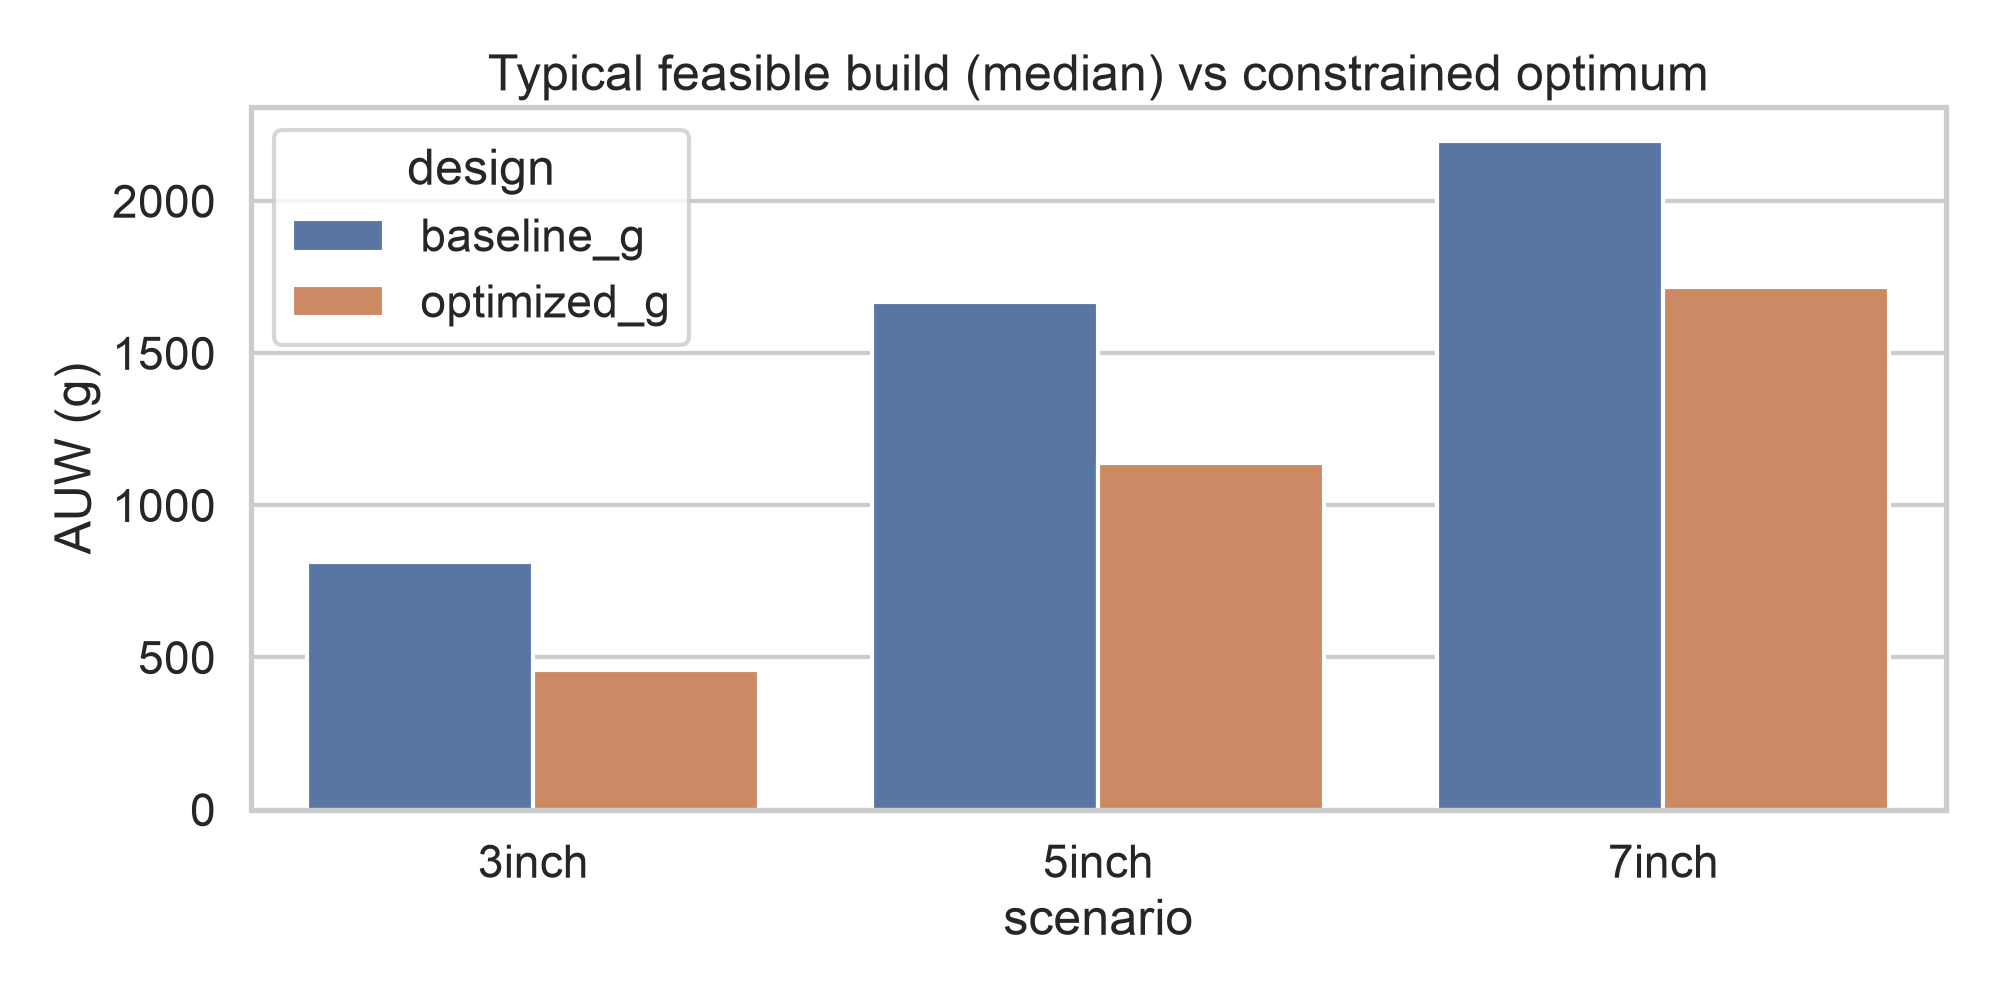

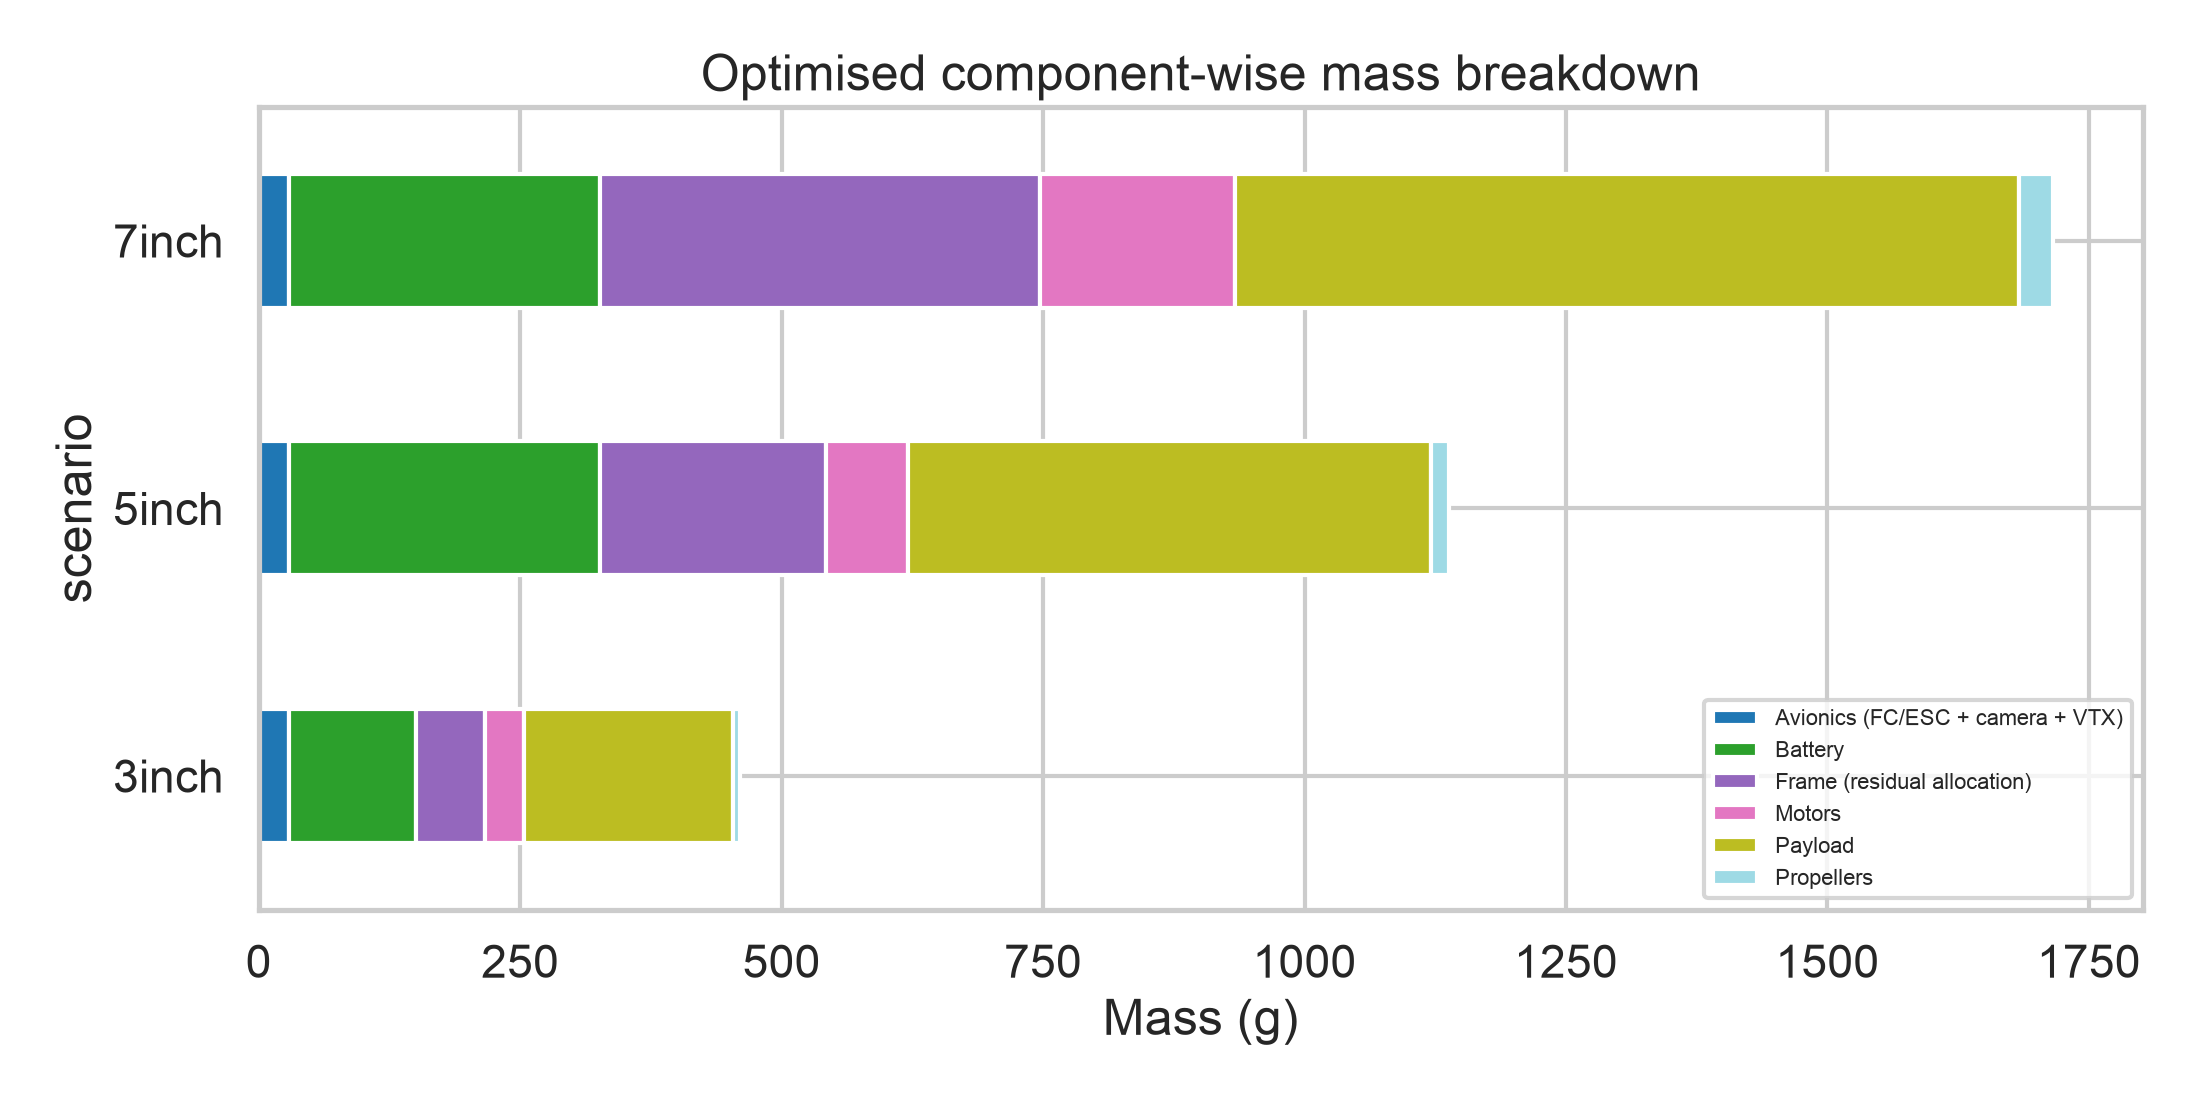

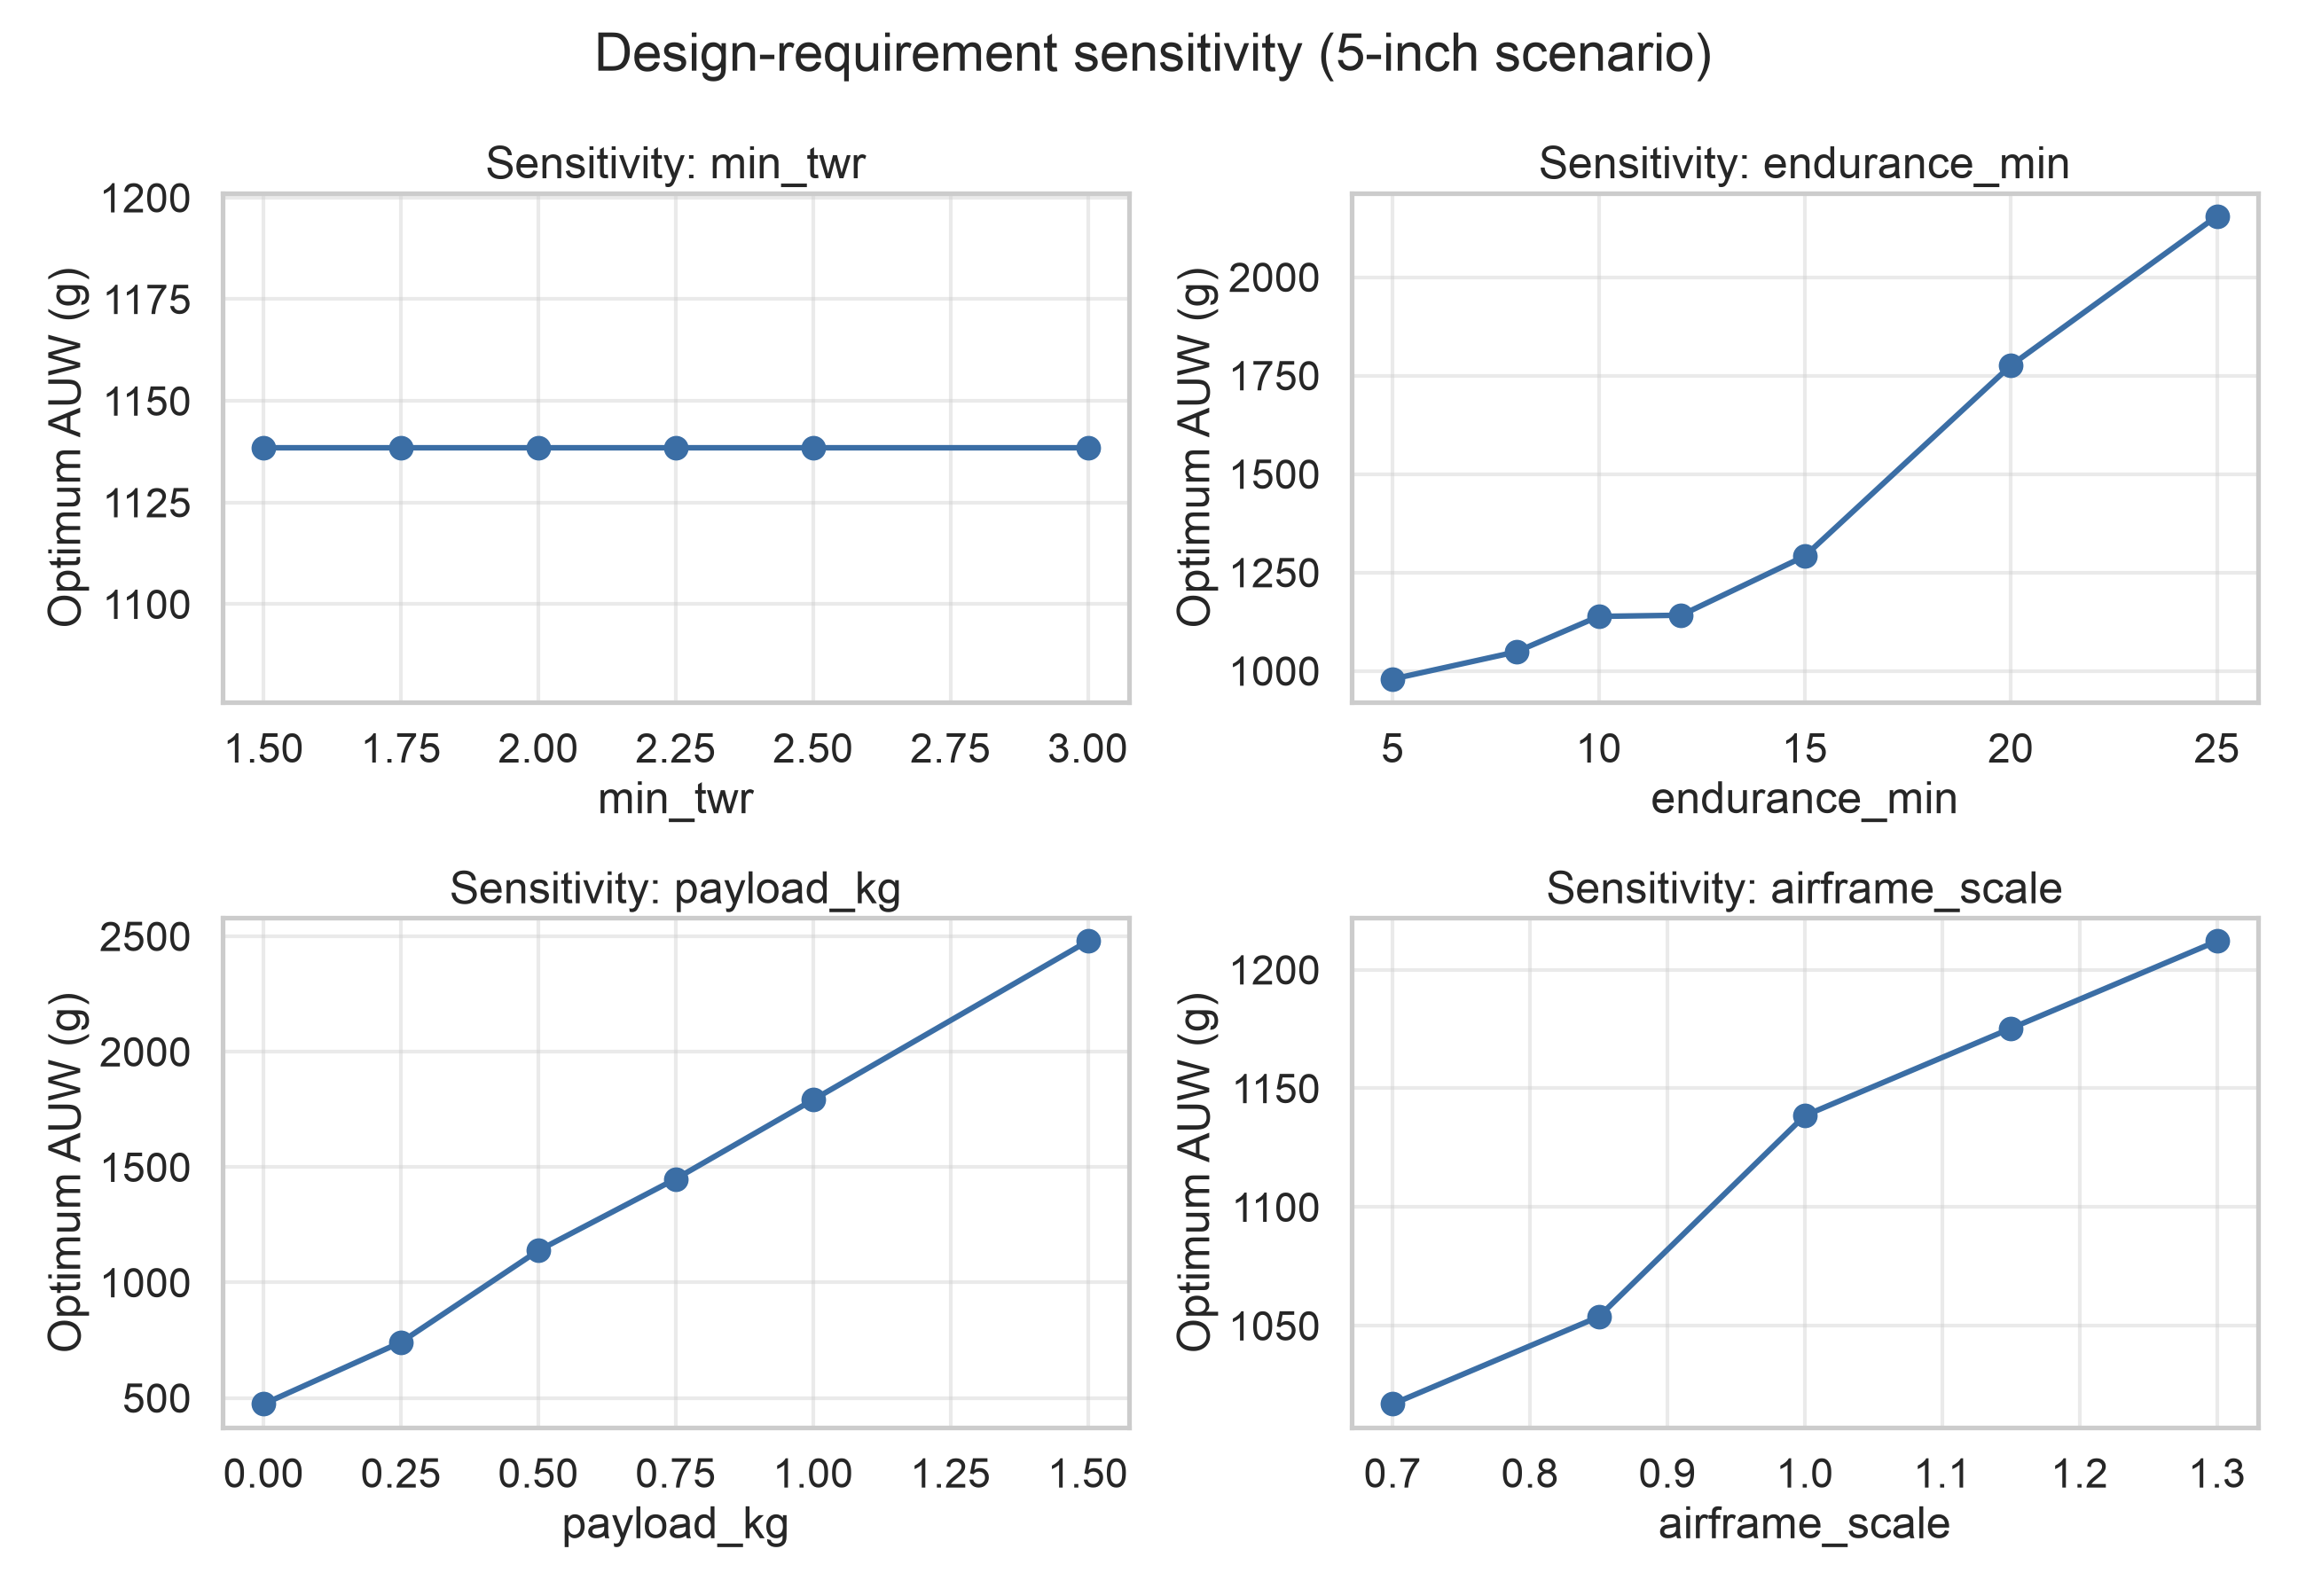

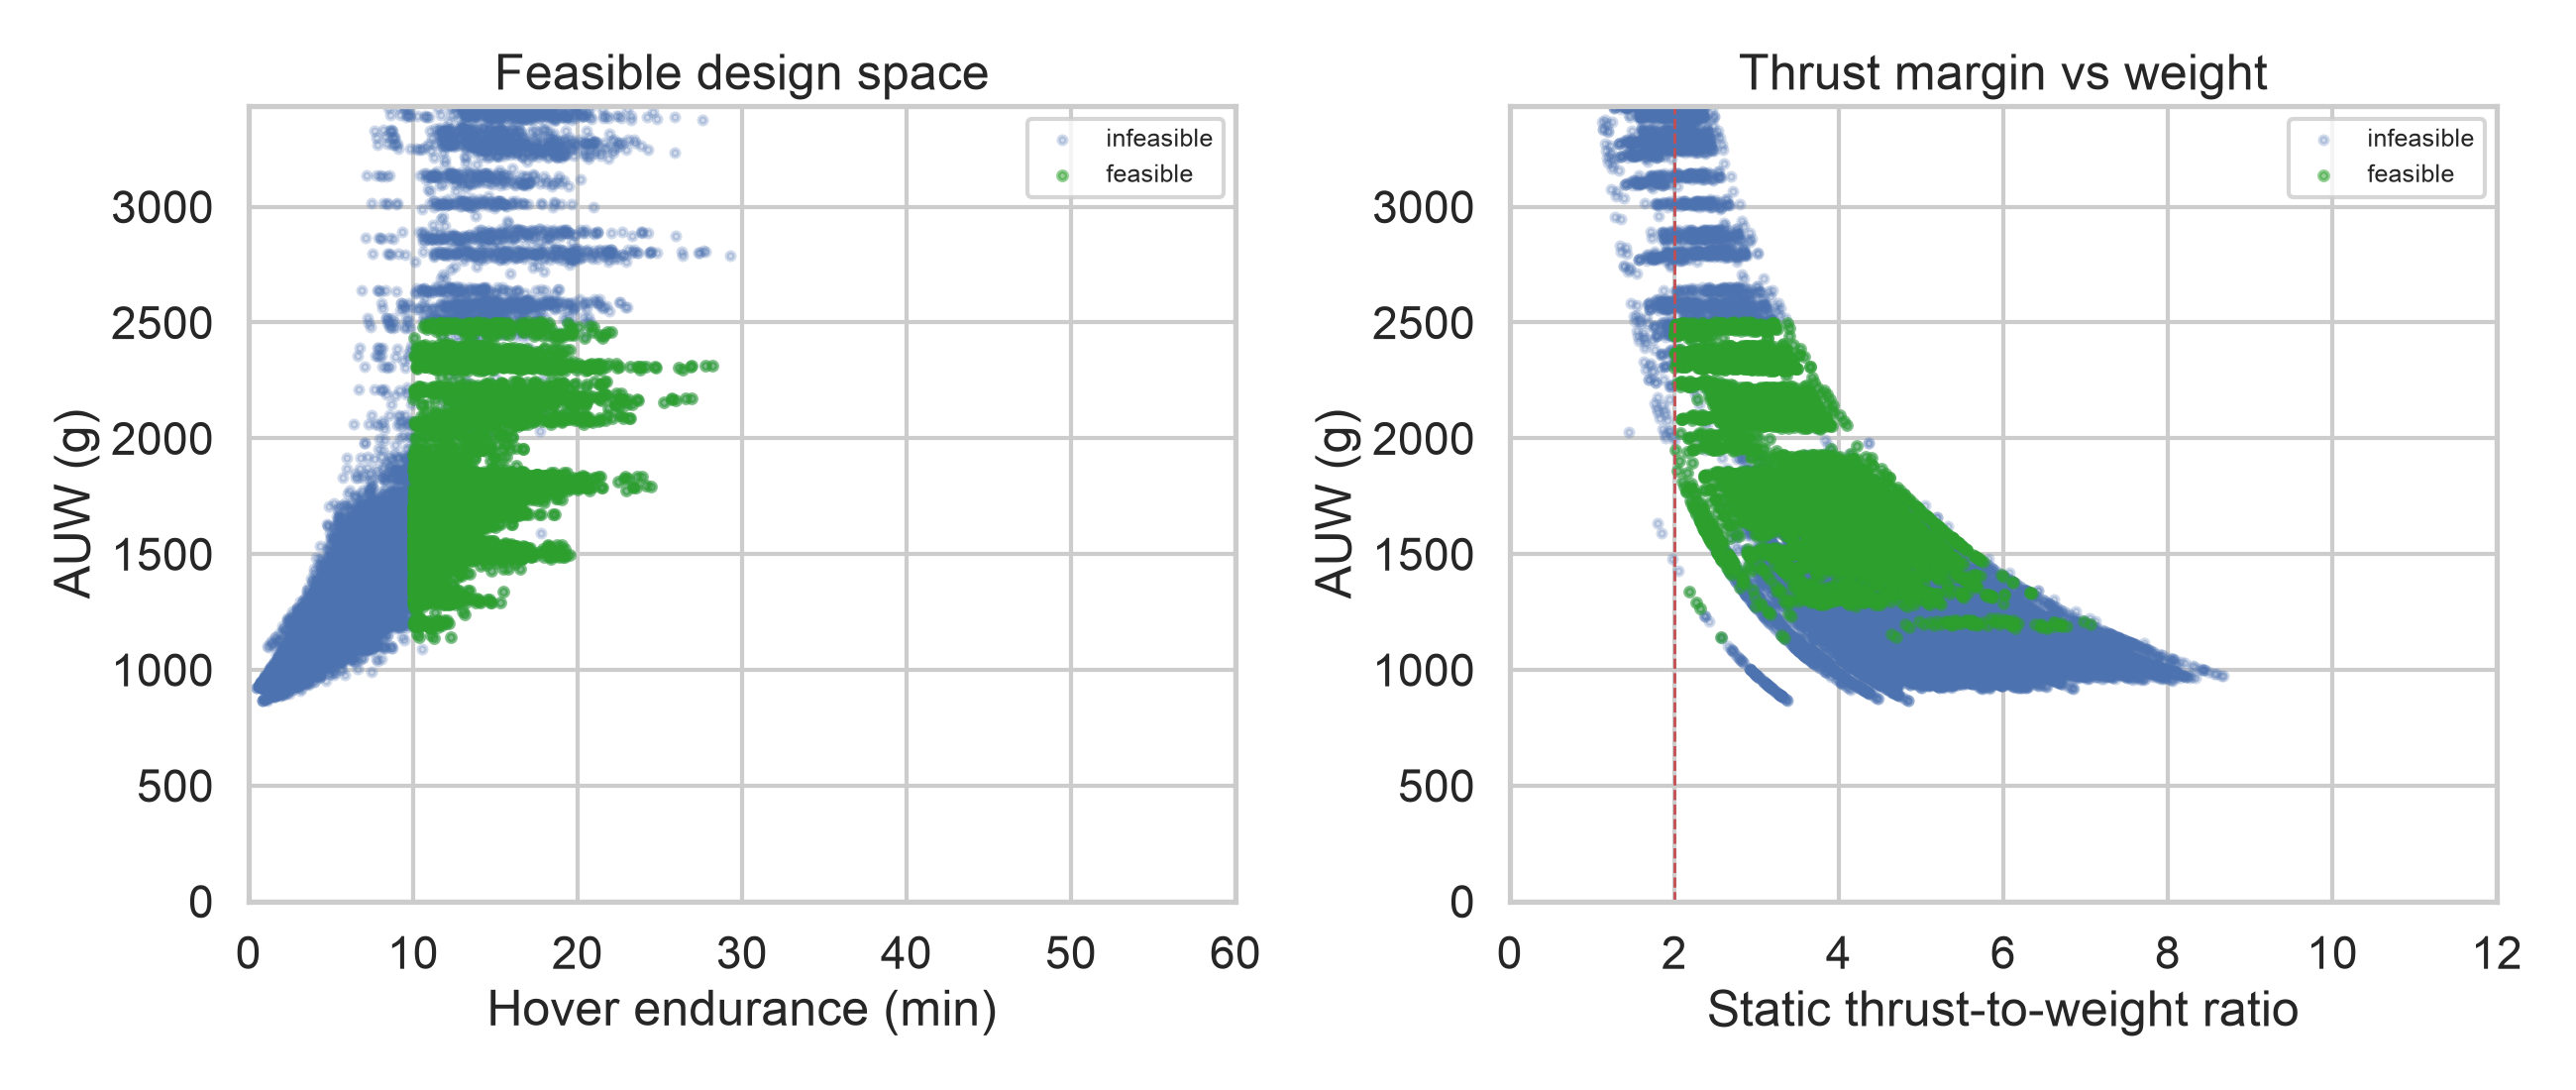

In [9]:
from IPython.display import Image, display
for f in ["convergence_curves","algorithm_comparison","original_vs_optimized",
          "optimized_component_breakdown","sensitivity_analysis","constraint_feasibility"]:
    display(Image(filename=f"../outputs/drone_weight/figures/{f}.png", width=850))

### Reading the sensitivity plots

* **Payload dominates**: 0 g → 474 g, 500 g → 1,139 g, 1,500 g → 2,479 g. The response is
  super-linear because payload cascades into propulsion and battery mass.
* **Endurance** is convex: 5 min → 980 g, 12 min → 1,142 g, 20 min → 1,776 g. Beyond ~12 min
  each extra minute costs disproportionately.
* **TWR** between 1.5 and 3.0 does not change the optimum: the selected design already has
  TWR 3.34, so **energy, not thrust, is the binding constraint** at this payload.
* **Airframe mass** shifts the optimum almost one-for-one, as expected from an additive objective.
* The **feasible design space** plot shows the green feasible region and the red TWR = 2 line;
  the optimum sits on the endurance boundary, not the thrust boundary.

## Limitations to carry into any decision

1. Frame mass is a design input, not a measured column (±30 % sensitivity provided).
2. Usable battery fraction η = 0.80 is an assumption; endurance scales linearly with it.
3. Bench thrust/current are steady-state at fixed voltage; voltage sag, heating and ESC losses
   are not modelled.
4. Payload is additive and drives C1/C2, but the dataset has no payload column to calibrate a
   payload-dependent mass cascade.
5. The catalogue is FPV/hobby class (≤ 2.2 kg); C6 caps results at 2.5 kg.
6. No structural stress model exists in the data; "structural integrity" is represented only by
   the frame-class prop range and the airframe mass input.